# 02 Linear models

In this notebook, we set the bar that the neural networks have to beat. We fit the baselines and the linear models
from the plan (`01-Research-and-Plan.md`) and compare them:

| Model | What changes | Why |
|---|---|---|
| Copy last year | Nothing is fitted | Kogan et al.'s baseline, so we can compare with the paper |
| Straight line | A slope and intercept on last year's log volatility | Uses last year's volatility as well as a one-number rule can |
| Ridge, pooled | Adds the averaged FinBERT vectors, fitted to what the line gets wrong, with all the training years together | Does the text help at all? |
| Ridge, within year | The same, but the text can only explain differences between companies in the same year | Removes the year-level effect found in section 2 |

Each ridge is run on Item 1, Item 7 and both. A ridge regression is a neural network with no hidden layer, so Louis's
MLP and the attention network have to beat it to show that the extra layers help.

Everything follows what Oscar set up in `report/02-Data.ipynb`: the data is `data.pkl`, the test years are 2001 to
2006 with the paper and strict training windows from `data/output/splits.csv`, and anything tuned is tuned on the
last training year. Every model is scored with `scoring.py` against the straight line, with a paired bootstrap over
the test reports (lecture 05.2, slide 14). Where the course covers a method we cite the lecture and slide, and go to
papers only for what it does not. The notebook takes about three minutes on a laptop CPU.

On Colab, the first cell connects Google Drive, gets the repo and copies `data.pkl`. Locally it does nothing.

In [1]:
import importlib.util, os, shutil, subprocess
from pathlib import Path

NOTEBOOK_DIR = "Alex"
if importlib.util.find_spec("google.colab") is not None:
    from google.colab import drive
    drive.mount("/content/drive")
    repo = Path("/content/dst-sprint2")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/Oscar339/dst-sprint2.git", str(repo)], check=True)
    processed = repo / "data" / "processed"
    processed.mkdir(parents=True, exist_ok=True)
    if not (processed / "data.pkl").exists():
        shutil.copy(Path("/content/drive/MyDrive/sprint2-data/data.pkl"), processed / "data.pkl")
    os.chdir(repo / NOTEBOOK_DIR)

In [2]:
import pickle, sys, time, platform
sys.path.insert(0, ".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import ridge_sums
import scoring

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__}")
with open("../data/processed/data.pkl", "rb") as f:   # Oscar's hand-over file (Oscar/make_handover.py)
    d = pickle.load(f)
df = scoring.frame(d)
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}, X {d['X'].shape}")

Python 3.13.17 | numpy 2.5.3 | pandas 3.0.6


27,142 reports, 1996-2006, X (27142, 1536)


## 1. The baselines

We score by mean squared error (the loss of lecture 02.1, slide 16) on log volatility rather than volatility itself,
as volatility is strongly skewed and the squared errors would be dominated by the few most volatile companies
(plan, section 2). Splitting by filing year rather than at random is lecture 02.2's way of handling data that are
correlated in time (slide 9). The cell below checks the skew, and that our windows match the shared
`data/output/splits.csv`.

The two baselines use last year's volatility only:

* Copy last year - predict `logvol_after = logvol_before`. This is the baseline in Kogan et al. (2009).
* Straight line - `logvol_after = a + b * logvol_before`, fitted on the training years. Volatility drifts back
  towards a typical level, so $b < 1$ is likely, and this line can beat copying without reading any text.

In [3]:
vol = np.exp(df["logvol_after"])
print(f"skewness: volatility {stats.skew(vol):.2f}, log volatility {stats.skew(df['logvol_after']):.2f}")

shared = pd.read_csv("../data/output/splits.csv")
for r in shared.itertuples():
    train, _ = scoring.masks(df, r.test_year, r.window)
    assert train.sum() == r.train_reports
assert set(shared.window) == set(scoring.WINDOWS)
print("the windows match data/output/splits.csv")

copy_vs_line = scoring.evaluate(df, scoring.predict_copy, name="copy last year")
baselines = copy_vs_line[copy_vs_line.window == "paper"].set_index("test_year")
baselines[["test_reports", "mse", "baseline_mse"]].rename(
    columns={"mse": "copy last year", "baseline_mse": "straight line"}).round(4)

skewness: volatility 3.33, log volatility 0.08
the windows match data/output/splits.csv


,test_reports,copy last year,straight line
test_year,,,
2001,2299,0.1468,0.1684
2002,2587,0.1334,0.1368
2003,3217,0.1550,0.1758
2004,3168,0.1092,0.0937
2005,3121,0.0971,0.0884
2006,3003,0.1034,0.0982


The line beats copying in 2004 to 2006 and loses in 2001 to 2003. Its slope is about 0.9 (section 3), which pulls
extreme volatilities towards the average and helps when the market is steady. But its intercept is learnt from the
training years, so it is off when the whole market moves, as it did around the 2000 to 2002 crash. We come back to
this in the next section.

## 2. Ridge on the averaged FinBERT vectors

Ridge regression is not in the course: it adds the penalty $\lambda\lVert\beta\rVert^2$ to the least squares problem
of lecture 02.1 (slide 18), and the plan (section 5) says why we chose it (Hastie, Tibshirani & Friedman, 2009,
§3.4). It is fitted in two stages (plan, section 6): the straight line first, then ridge on the standardised
averaged chunk vectors to what the line gets wrong, so ridge only has to find what the text adds. The penalty
$\lambda$ is chosen on the last training year - fit on the other years in the window, score that year, keep the best
$\lambda$ and refit on the whole window. This keeps to lecture 02.2's rule that held-out data can score a model but
never influence it (slide 7); choosing $\lambda$ on the test year would be the double dipping of lecture 05.2
(slide 19). The networks use the same year to stop training.

**Pooled or within year.** Our first version fitted all the training years together, and its error swung a lot
from one test year to the next. The reason is that the MSE on a test year splits exactly into two parts:

$$\text{MSE} = \underbrace{\bar e^{\,2}}_{\text{level}} + \underbrace{\tfrac1n\textstyle\sum_i (e_i - \bar e)^2}_{\text{spread}}$$

* Level - how far off the model is about the whole year's volatility. This is the same for every company, so no
  single report can know it.
* Spread - how well the model ranks the companies within the year, which is the part the text could help with.

The wording of 10-Ks drifts over time, so the text vectors partly say which era a report is from, and the pooled
ridge used that to guess the level. The within-year version takes each year's average off the residual and the text
vectors before fitting, and centres the test year's vectors on their own average (other companies' text, never their
volatility). Its text part then averages zero in every test year, so it can only change how companies are ranked.

**Fitting from per-year sums.** Ridge only needs a few sums over the training reports ($X^\top X$, $X^\top y$ and
some totals), and sums add up. So `ridge_sums.py` computes them once per filing year and adds up the years in a
window. This is the map/reduce pattern of lecture 09.2 (slides 10 to 11): the year is the key, the per-year sums are
the mapper's output, and adding them is the reduce step, which can be done in any order because addition is
associative and commutative (slide 8). After that each fit is one eigen-decomposition of a 1,536 × 1,536 matrix, so
it costs $O(p^3)$ whatever the number of reports (big-O as in lecture 08.1), and the $O(np^2)$ pass over the reports
happens once. Section 4 checks it against scikit-learn.

In [4]:
INPUTS = {"Item 1": d["X"][:, :768], "Item 7": d["X"][:, 768:], "both": d["X"]}   # data.pkl: Item 1, then Item 7
t = time.perf_counter()
SUMS_BOTH = ridge_sums.year_sums(d["X"], df)                                  # map: one job per filing year
SUMS = {"both": SUMS_BOTH, "Item 1": ridge_sums.subset(SUMS_BOTH, np.arange(768)),
        "Item 7": ridge_sums.subset(SUMS_BOTH, np.arange(768, 1536))}
print(f"map: per-year sums in {time.perf_counter() - t:.1f}s")

ALPHAS = np.logspace(0, 9, 37)
x_all, yr_all = df["logvol_before"].to_numpy(), df["year"].to_numpy()
chosen = []

def make_ridge(label, within_year):
    def predict(df, train, test):
        a, b = scoring.fit_line(df, train)
        model = ridge_sums.fit(SUMS[label], sorted(set(yr_all[train])), a, b, ALPHAS, within_year=within_year)
        chosen.append(model["alpha"])
        return a + b * x_all[test] + ridge_sums.predict(model, INPUTS[label][test])
    return predict

t = time.perf_counter()
pooled_results = pd.concat([scoring.evaluate(df, make_ridge(lab, False), name=f"pooled ridge, {lab}") for lab in INPUTS],
                           ignore_index=True)
within_results = pd.concat([scoring.evaluate(df, make_ridge(lab, True), name=f"within-year ridge, {lab}") for lab in INPUTS],
                           ignore_index=True)
print(f"{len(pooled_results) + len(within_results)} fits in {time.perf_counter() - t:.0f}s")
print("lambda chosen on the last training year:", pd.Series(chosen).value_counts().sort_index().to_dict())

# The level/spread split, paper window, Item 7: change in MSE against the line, in % of the line's MSE
rows = {"line: level as % of its MSE": 100 * baselines["baseline_level"] / baselines["baseline_mse"]}
for name, res in [("pooled", pooled_results), ("within-year", within_results)]:
    r = res[(res.model == f"{name} ridge, Item 7") & (res.window == "paper")].set_index("test_year")
    rows[f"{name} ridge: change from the level"] = 100 * (r["level"] - r["baseline_level"]) / r["baseline_mse"]
    rows[f"{name} ridge: change from the spread"] = 100 * (r["spread"] - r["baseline_spread"]) / r["baseline_mse"]
pd.DataFrame(rows).T.round(1)

map: per-year sums in 1.9s


72 fits in 126s
lambda chosen on the last training year: {1000.0: 3, 1778.2794100389228: 6, 3162.2776601683795: 8, 5623.413251903491: 12, 10000.0: 6, 17782.794100389227: 2, 56234.13251903491: 4, 100000.0: 3, 177827.94100389228: 3, 316227.7660168379: 1, 562341.3251903491: 1, 1778279.410038923: 3, 3162277.6601683795: 2, 5623413.251903491: 2, 10000000.0: 2, 17782794.100389227: 2, 31622776.60168379: 1, 1000000000.0: 11}


test_year,2001,2002,2003,2004,2005,2006
line: level as % of its MSE,29.9,4.4,44.3,8.4,0.1,1.0
pooled ridge: change from the level,8.8,0.0,-19.3,-8.3,3.5,0.0
pooled ridge: change from the spread,-1.9,-0.0,0.9,3.8,1.0,-0.0
within-year ridge: change from the level,-0.0,-0.0,-0.0,0.0,-0.0,-0.0
within-year ridge: change from the spread,-1.8,-5.6,1.0,0.6,-0.0,-0.4


The pooled ridge's big gains and losses are almost all level, and the within-year ridge's level change is zero by
construction, so what is left is what the text says about the company. Below are the within-year results: the change
in MSE against the line (negative is better), and the number of test years whose whole 95% interval is below zero.

mean_change_pct  best_year  worst_year  \
model                     window                                           
within-year ridge, Item 1 paper              -0.5       -3.0         1.0   
                          strict              0.3       -1.9         4.7   
within-year ridge, Item 7 paper              -1.0       -5.6         1.0   
                          strict             -0.0       -4.4         6.1   
within-year ridge, both   paper              -0.7       -4.7         1.8   
                          strict              0.2       -3.5         6.6   

                                  years_better  years_significant  
model                     window                                   
within-year ridge, Item 1 paper              4                  3  
                          strict             5                  3  
within-year ridge, Item 7 paper              4                  3  
                          strict             4                  3  
within-year ridge, both   paper              4                  3  
                          strict             4                  3

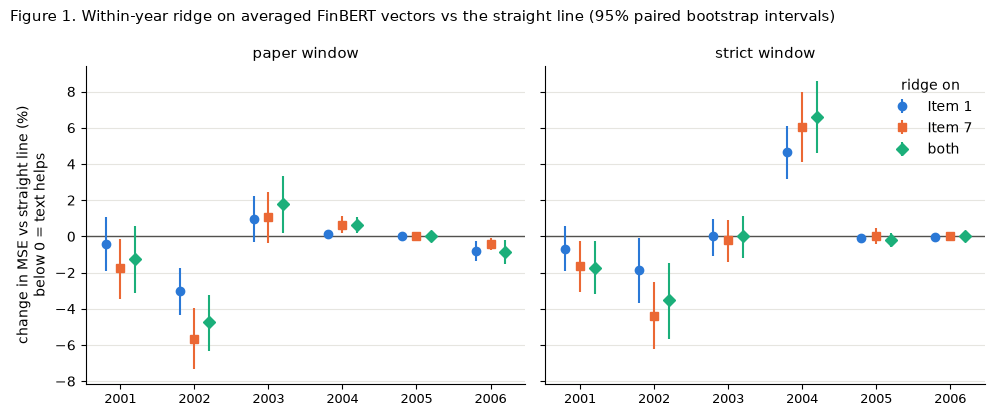

In [5]:
summary = (within_results.groupby(["model", "window"], sort=False)
           .agg(mean_change_pct=("change_pct", "mean"), best_year=("change_pct", "min"),
                worst_year=("change_pct", "max"), years_better=("change_pct", lambda c: int((c < 0).sum())),
                years_significant=("ci_high", lambda h: int((h < 0).sum())))
           .round(1))
display(summary)

COLORS = {"Item 1": "#2a78d6", "Item 7": "#eb6834", "both": "#1baf7a"}   # fixed order: series 1, 2, 3
MARKERS = {"Item 1": "o", "Item 7": "s", "both": "D"}                    # second cue besides colour
OFFSET = {"Item 1": -0.2, "Item 7": 0.0, "both": 0.2}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, window in zip(axes, scoring.WINDOWS):
    ax.axhline(0, color="#52514e", lw=1)
    for lab in INPUTS:
        r = within_results[(within_results.model == f"within-year ridge, {lab}") & (within_results.window == window)]
        pct, lo, hi = r.change_pct, 100 * r.ci_low / r.baseline_mse, 100 * r.ci_high / r.baseline_mse
        ax.errorbar(r.test_year + OFFSET[lab], pct, yerr=[pct - lo, hi - pct], fmt=MARKERS[lab],
                    color=COLORS[lab], ms=6, lw=1.5, capsize=0, label=lab)
    ax.set_title(f"{window} window", fontsize=11)
    ax.set_xticks(list(scoring.TEST_YEARS))
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("change in MSE vs straight line (%)\nbelow 0 = text helps")
axes[-1].legend(title="ridge on", frameon=False, loc="best")
fig.suptitle("Figure 1. Within-year ridge on averaged FinBERT vectors vs the straight line (95% paired bootstrap intervals)",
             fontsize=11, x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 3. Comparison with Kogan et al. (2009)

Kogan et al.'s baseline is copying last year, so we can recompute it from their public label files and check that
our data and scoring match theirs. We do it on all of their reports, on ours (the 89% matched to EDGAR-CORPUS) and
on the 11% we dropped.

In [6]:
import urllib.request

kogan_dir = Path("../data/raw/kogan")                 # same place Oscar/02-Merge-Kogan-EDGAR.ipynb downloads to
kogan_dir.mkdir(parents=True, exist_ok=True)
for yr in range(1996, 2007):
    for f in ["logvol.-12.txt", "logvol.+12.txt"]:
        target = kogan_dir / f"{yr}.{f}"
        if not target.exists():
            urllib.request.urlretrieve(f"https://www.cs.cmu.edu/~ark/10K/data/{target.name}", target)

def read_logvol(yr, sign):
    return (pd.read_csv(kogan_dir / f"{yr}.logvol.{sign}12.txt", sep=" ", header=None, names=["v", "key"])
            .drop_duplicates("key").set_index("key")["v"])

PAPER = {2001: (2596, 0.1747), 2002: (2846, 0.1600), 2003: (3612, 0.1873),     # Kogan et al. (2009), Table 2:
         2004: (3559, 0.1442), 2005: (3474, 0.1365), 2006: (3308, 0.1463)}     # (test reports, baseline MSE)
rows = []
for yr in scoring.TEST_YEARS:
    k = pd.DataFrame({"before": read_logvol(yr, "-"), "after": read_logvol(yr, "+")}).dropna()
    se = (k["after"] - k["before"]) ** 2
    ours = k.index.isin(df["key"])
    rows.append({"test_year": yr, "paper: reports": PAPER[yr][0], "paper: copy MSE": PAPER[yr][1],
                 "public: reports": len(k), "public: copy MSE": se.mean(),
                 "ours: reports": int(ours.sum()), "ours: copy MSE": se[ours].mean(),
                 "dropped: reports": int((~ours).sum()), "dropped: copy MSE": se[~ours].mean(),
                 "ours: mean logvol": k["after"][ours].mean(), "dropped: mean logvol": k["after"][~ours].mean()})
coverage = pd.DataFrame(rows).set_index("test_year")
coverage.round(4)

,paper: reports,paper: copy MSE,public: reports,public: copy MSE,ours: reports,ours: copy MSE,dropped: reports,dropped: copy MSE,ours: mean logvol,dropped: mean logvol
test_year,,,,,,,,,,
2001,2596,0.1747,2596,0.1747,2299,0.1468,297,0.3905,-3.1990,-3.0154
2002,2846,0.1600,2845,0.1600,2587,0.1334,258,0.4273,-3.2356,-3.1786
2003,3612,0.1873,3611,0.1873,3217,0.1550,394,0.4512,-3.5477,-3.5043
2004,3559,0.1442,3558,0.1442,3168,0.1092,390,0.4285,-3.6996,-3.7429
2005,3474,0.1365,3474,0.1365,3121,0.0971,353,0.4847,-3.7689,-3.8031
2006,3308,0.1463,3306,0.1464,3003,0.1034,303,0.5729,-3.8077,-3.9423


On all of their reports, copying gives exactly the paper's numbers, so our data and scoring match theirs. But the
reports we dropped have 3 to 6 times the error - their volatility changed much more between the two years - so our
MSEs are 16 to 29% lower than the paper's for reasons that have nothing to do with any model. Comparisons have to be
against a baseline on the same reports. The same applies to FETILDA (Xia et al., 2022), whose 27% improvement on
Kogan's baseline is measured on a different subset of test reports.

The paper never fitted a working line on last year's volatility (its attempt, with support vector regression, scored
5.68 in 2006). The labels exist for every public report, so we fit the line on Kogan's full data with their training
window and put it next to their text models:

In [7]:
KOGAN = {"TF+ (Kogan)":            [0.1885, 0.1616, 0.1925, 0.1230, 0.1272, 0.1402],   # Table 2, text + history
         "LOG1P+ bigrams (Kogan)": [0.1852, 0.1792, 0.1599, 0.1352, 0.1307, 0.1448]}
all_results = pd.concat([copy_vs_line, pooled_results, within_results], ignore_index=True)
all_results.to_csv("../data/output/alex-02-ridge-results.csv", index=False)   # for the report and other notebooks

full = pd.concat([pd.DataFrame({"before": read_logvol(yr, "-"), "after": read_logvol(yr, "+"), "year": yr}).dropna()
                  for yr in range(1996, 2007)])
rows = []
for i, T in enumerate(scoring.TEST_YEARS):
    tr, te = full[full.year.between(T - 5, T - 1)], full[full.year == T]
    b, a = np.polyfit(tr["before"], tr["after"], 1)
    line = np.mean((te["after"] - (a + b * te["before"])) ** 2)
    rows.append({"test_year": T, "test reports": len(te), "copy (paper's baseline)": PAPER[T][1],
                 "straight line, no text": line, "TF+ (Kogan, text + history)": KOGAN["TF+ (Kogan)"][i],
                 "LOG1P+ bigrams (Kogan)": KOGAN["LOG1P+ bigrams (Kogan)"][i], "line slope": b})
full_line = pd.DataFrame(rows).set_index("test_year")
full_line["text beyond the line, TF+ (%)"] = 100 * (full_line["TF+ (Kogan, text + history)"] / full_line["straight line, no text"] - 1)
full_line.round(4)

,test reports,copy (paper's baseline),"straight line, no text","TF+ (Kogan, text + history)",LOG1P+ bigrams (Kogan),line slope,"text beyond the line, TF+ (%)"
test_year,,,,,,,
2001,2596,0.1747,0.1922,0.1885,0.1852,0.8913,-1.9199
2002,2845,0.1600,0.1631,0.1616,0.1792,0.8630,-0.8981
2003,3611,0.1873,0.2040,0.1925,0.1599,0.8694,-5.6248
2004,3558,0.1442,0.1272,0.1230,0.1352,0.9144,-3.3327
2005,3474,0.1365,0.1275,0.1272,0.1307,0.9027,-0.2084
2006,3306,0.1463,0.1403,0.1402,0.1448,0.8629,-0.0942


With no text at all, the line scores 0.1403 in 2006 against 0.1402 for TF+, the paper's best text model. So nearly
all of the paper's improvement over copying in 2004 to 2006 comes from fitting last year's volatility, not from the
text. Against the line, TF+ adds 0 to 6%, and LOG1P+ with bigrams is worse than the line in four of the six years.

## 4. Check against scikit-learn

The per-year sums should give exactly what scikit-learn gives on the reports themselves. For one window (strict,
2006, Item 7) and both versions, we redo the choice of $\lambda$ on the last training year with `StandardScaler` and
`Ridge`, and compare the validation curve and the test predictions.

In [8]:
import warnings
from scipy.linalg import LinAlgWarning
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=LinAlgWarning)   # scikit-learn warns at the very largest lambdas; the answers still agree

def demean_by_year(a, years):
    return a - pd.DataFrame(a).groupby(years).transform("mean").to_numpy()

def sklearn_ridge(rows, rows_out, alpha, a, b, within):
    r, X_fit, X_out = df["logvol_after"].to_numpy()[rows] - (a + b * x_all[rows]), INPUTS["Item 7"][rows], INPUTS["Item 7"][rows_out]
    if within:
        r, X_fit, X_out = demean_by_year(r[:, None], yr_all[rows])[:, 0], demean_by_year(X_fit, yr_all[rows]), X_out - X_out.mean(0)
    scaler = StandardScaler().fit(X_fit)
    return Ridge(alpha=alpha).fit(scaler.transform(X_fit), r).predict(scaler.transform(X_out))

train, test = scoring.masks(df, 2006, "strict")
years = sorted(set(yr_all[train]))
fit_rows, val_rows = np.isin(yr_all, years[:-1]), yr_all == years[-1]
a_s, b_s = scoring.fit_line(df, fit_rows)
a, b = scoring.fit_line(df, train)
y_all = df["logvol_after"].to_numpy()
rows = []
for within in [False, True]:
    model = ridge_sums.fit(SUMS["Item 7"], years, a, b, ALPHAS, within_year=within)
    curve = [np.mean((y_all[val_rows] - (a_s + b_s * x_all[val_rows])
                      - sklearn_ridge(fit_rows, val_rows, al, a_s, b_s, within)) ** 2) for al in ALPHAS]
    p_sk = sklearn_ridge(train, test, model["alpha"], a, b, within)
    rows.append({"version": "within-year" if within else "pooled",
                 "largest difference in the validation curve": np.abs(np.array(curve) - model["curve"]).max(),
                 "lambda (sums)": model["alpha"], "lambda (scikit-learn)": ALPHAS[int(np.argmin(curve))],
                 "largest difference in test predictions": np.abs(ridge_sums.predict(model, INPUTS["Item 7"][test]) - p_sk).max()})
pd.DataFrame(rows)

,version,largest difference in the validation curve,lambda (sums),lambda (scikit-learn),largest difference in test predictions
0,pooled,1.907378e-06,3.162278e+07,3.162278e+07,1.091811e-09
1,within-year,4.052335e-07,1.000000e+09,1.000000e+09,2.029362e-10


## 5. What this shows

The results below come from the saved run of this notebook. Nothing in it is random apart from the bootstrap, which
is seeded, so it gives the same numbers every time.

* Most of the error is the year, not the company. For the line, the level is 44% of the MSE in 2003 and 30% in 2001
  (section 2). Fitted on all the training years together, ridge swings from 26% better than the line to 16% worse,
  and its biggest gain (2003) is almost all level - 19 points from the level against 1 from the spread. The text was
  being used to guess the year. `scoring.evaluate` reports the level and spread for every model, so the networks can
  be checked for the same thing.
* Within a year, the averaged FinBERT vectors add little. The within-year ridge changes the MSE by −6% to +7% in
  single years and by −1.0% to +0.3% on average (section 2). Item 7 helps in 2001 and 2002, by 2 to 6%, the text
  hurts in 2004, by up to 6%, and in the other years the change is under 2%. In 11 of the 72 fits the last training
  year chose the largest $\lambda$, which switches the text off. Some of the small changes count as significant, as
  the paired bootstrap is very precise about them, but a change under 1% is not worth having. Item 7 alone does as
  well as both sections together.
* The paper's headline gain is mostly the fitted line (section 3). On Kogan's own data, a line with no text matches
  their best text model in 2005 and 2006, and the reports we dropped are the hard cases, with 3 to 6 times the error.
* The per-year sums are exact (section 4). The validation curves agree with scikit-learn to about $10^{-6}$ and the
  test predictions to about $10^{-9}$, and each fit takes well under a second.

So the bar for the neural networks is the within-year ridge on the same inputs. A network that beats the line but not
the ridge has not shown that its hidden layers help. As ridge does not clearly beat the line, there are two things to
test (plan, section 8): averaging may drown out the few chunks that are about risk, which the attention network
tests, or the vectors themselves may be the wrong ones.

Next, `03-Attention-network.ipynb`.

## References

- Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning*, 2nd ed., §3.4 (shrinkage methods). Springer.
- Kogan, S., Levin, D., Routledge, B. R., Sagi, J. S. & Smith, N. A. (2009). Predicting risk from financial reports with regression. *NAACL-HLT 2009*, 272–280. https://aclanthology.org/N09-1031/
- Xia, B., Rawte, V. D., Zaki, M. J. & Gupta, A. (2022). FETILDA: An effective framework for fin-tuned embeddings for long financial text documents. *arXiv:2206.06952*.

Course material (Data Science Toolbox, University of Bristol, 2026):

- Lecture 02.1, Towards Modern Regression. https://dsbristol.github.io/dst/assets/slides/02.1-ModernRegression.pdf
- Lecture 02.2, Cross Validation. https://dsbristol.github.io/dst/assets/slides/02.2-CrossValidation.pdf
- Lecture 05.2, Towards Modern Statistical Testing. https://dsbristol.github.io/dst/assets/slides/05.2-StatisticalTesting.pdf
- Lecture 08.1, Analysing Algorithms. https://dsbristol.github.io/dst/coursebook/08.html
- Lecture 09.2, Mapping, Reducing, and Computational Graphs. https://dsbristol.github.io/dst/assets/slides/09.2-ComputationalGraphs.pdf